# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Teesha kumari
- **Student ID:** 023-23-0195
- **GitHub:**https://github.com/TeeshaMahesh
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:**https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, time, warnings

In [2]:
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Downloaded to:", path)
print("Files:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Downloaded to: /kaggle/input/telco-customer-churn
Files: ['WA_Fn-UseC_-Telco-Customer-Churn.csv']
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import os, pandas as pd, kagglehub


path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
print("Loaded shape:", df.shape)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())


df["TotalCharges"] = df["TotalCharges"].fillna(0)


df = df.drop(columns=["customerID"], errors="ignore")


df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})


df = pd.get_dummies(df, drop_first=True)
df = df.astype(float)

print("Shape after cleaning:", df.shape)
print(df["Churn"].value_counts(normalize=True))




Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Loaded shape: (7043, 21)
Missing TotalCharges: 11
Shape after cleaning: (7043, 31)
Churn
0.0    0.73463
1.0    0.26537
Name: proportion, dtype: float64


In [15]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Split the data (stratify=y keeps the churn ratio equal in train and test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # use the same value as in Labs 3/4/6
    random_state=42,     # use the same value as in Labs 3/4/6
    stratify=y
)

# Sanity checks
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Features count:", X.shape[1])
print("Train churn ratio:", round(y_train.mean(), 3))
print("Test churn ratio :", round(y_test.mean(), 3))

X_train: (5634, 30) | X_test: (1409, 30)
Features count: 30
Train churn ratio: 0.265
Test churn ratio : 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [16]:
# YOUR CODE HERE — unscaled linear SVM
import time, warnings
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

# Train a linear SVM on the UN-scaled encoded features
svm_raw = SVC(kernel="linear", random_state=42, max_iter=200000)

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")        # capture every warning
    start = time.time()
    svm_raw.fit(X_train, y_train)
    time_raw = time.time() - start

# Did the optimizer hit the iteration limit?
conv_warn_raw = any("converge" in str(x.message).lower() for x in w)

# Evaluate on the test set
y_pred_raw = svm_raw.predict(X_test)
acc_raw = accuracy_score(y_test, y_pred_raw)
f1_raw = f1_score(y_test, y_pred_raw)

print("UNSCALED linear SVM")
print("Accuracy           :", round(acc_raw, 4))
print("F1-score           :", round(f1_raw, 4))
print("Train time (s)     :", round(time_raw, 2))
print("Convergence warning:", conv_warn_raw)
print("Support vectors    :", svm_raw.support_.shape[0])

UNSCALED linear SVM
Accuracy           : 0.4017
F1-score           : 0.2343
Train time (s)     : 14.68
Convergence warning: False
Support vectors    : 1038


In [17]:
# YOUR CODE HERE — scaled linear SVM
import time, warnings
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# Scale the features: fit on TRAIN only, transform both train and test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)          # transform only, never fit on test

# Train a linear SVM on the SCALED features (same max_iter as the unscaled run)
svm_scaled = SVC(kernel="linear", random_state=42, max_iter=200000)

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")        # capture every warning
    start = time.time()
    svm_scaled.fit(X_train_s, y_train)
    time_scaled = time.time() - start

# Did the optimizer hit the iteration limit?
conv_warn_scaled = any("converge" in str(x.message).lower() for x in w)

# Evaluate on the test set
y_pred_scaled = svm_scaled.predict(X_test_s)
acc_scaled = accuracy_score(y_test, y_pred_scaled)
f1_scaled = f1_score(y_test, y_pred_scaled)

print("SCALED linear SVM")
print("Accuracy           :", round(acc_scaled, 4))
print("F1-score           :", round(f1_scaled, 4))
print("Train time (s)     :", round(time_scaled, 2))
print("Convergence warning:", conv_warn_scaled)
print("Support vectors    :", svm_scaled.support_.shape[0])

SCALED linear SVM
Accuracy           : 0.7885
F1-score           : 0.5694
Train time (s)     : 4.25
Convergence warning: False
Support vectors    : 2567


In [18]:
# fit_status_ == 1 means the solver stopped because it hit max_iter
print("Unscaled fit_status_:", svm_raw.fit_status_)
print("Scaled   fit_status_:", svm_scaled.fit_status_)
print("Unscaled iterations :", svm_raw.n_iter_)
print("Scaled   iterations :", svm_scaled.n_iter_)
print("Majority-class baseline accuracy:", round(1 - y_test.mean(), 4))

Unscaled fit_status_: 1
Scaled   fit_status_: 0
Unscaled iterations : [200000]
Scaled   iterations : [73860]
Majority-class baseline accuracy: 0.7346


In [19]:
comparison_p1 = pd.DataFrame([
    {"Model": "Linear SVM (unscaled)", "Accuracy": round(acc_raw, 4), "F1-score": round(f1_raw, 4),
     "Train time (s)": round(time_raw, 2), "Hit max_iter?": bool(svm_raw.fit_status_ == 1),
     "Iterations": int(svm_raw.n_iter_[0]), "Support vectors": svm_raw.support_.shape[0]},
    {"Model": "Linear SVM (scaled)", "Accuracy": round(acc_scaled, 4), "F1-score": round(f1_scaled, 4),
     "Train time (s)": round(time_scaled, 2), "Hit max_iter?": bool(svm_scaled.fit_status_ == 1),
     "Iterations": int(svm_scaled.n_iter_[0]), "Support vectors": svm_scaled.support_.shape[0]},
])
comparison_p1

,Model,Accuracy,F1-score,Train time (s),Hit max_iter?,Iterations,Support vectors
0,Linear SVM (unscaled),0.4017,0.2343,14.68,True,200000,1038
1,Linear SVM (scaled),0.7885,0.5694,4.25,False,73860,2567


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:*) Unscaled: accuracy 0.4017, F1 0.2343. Scaled: accuracy 0.7885, F1 0.5694. The unscaled model is below the 0.7346 majority baseline and hit the max_iter limit (fit_status_ = 1), while the scaled model converged (fit_status_ = 0). Training took 14.68 s unscaled (cut off by the limit) versus 4.25 s scaled.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*Margin and dot products depend on feature magnitude. Large-range features (TotalCharges up to ~8,000) dominate, so the problem is badly conditioned and the solver never finds a good hyperplane. After StandardScaler all features have comparable influence.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* I will use the scaled features (X_train_s, X_test_s) for every later SVM, because margins and kernels are distance-based. The scaler is fit on train only, so there is no data leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [20]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

kernels = ["linear", "rbf", "poly"]
rows, models, preds = [], {}, {}

for k in kernels:
    model = SVC(kernel=k, random_state=42)    # same random_state, default C and gamma
    start = time.time()
    model.fit(X_train_s, y_train)             # scaled train split
    t = time.time() - start

    y_pred = model.predict(X_test_s)
    models[k], preds[k] = model, y_pred

    rows.append({
        "Kernel": k,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-score": round(f1_score(y_test, y_pred), 4),
        "Support vectors": model.support_.shape[0],
        "Train time (s)": round(t, 2),
    })

print("Done. Trained:", list(models.keys()))

Done. Trained: ['linear', 'rbf', 'poly']


In [21]:
# YOUR CODE HERE — comparison table
kernel_table = pd.DataFrame(rows)
kernel_table

,Kernel,Accuracy,Precision,Recall,F1-score,Support vectors,Train time (s)
0,linear,0.7885,0.6195,0.5267,0.5694,2567,2.27
1,rbf,0.7928,0.6444,0.4893,0.5562,2657,3.18
2,poly,0.7892,0.6421,0.4652,0.5395,2736,2.75


Best kernel by F1: linear


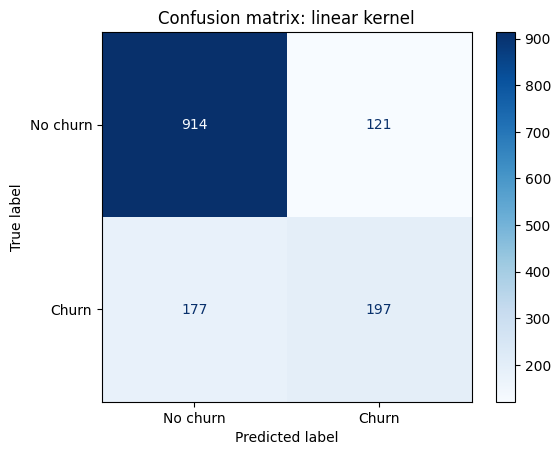

In [22]:
# YOUR CODE HERE — confusion matrix for the best kernel
# Pick the kernel with the highest F1-score automatically
best_kernel = kernel_table.loc[kernel_table["F1-score"].idxmax(), "Kernel"]
print("Best kernel by F1:", best_kernel)

ConfusionMatrixDisplay.from_predictions(
    y_test, preds[best_kernel],
    display_labels=["No churn", "Churn"], cmap="Blues"
)
plt.title(f"Confusion matrix: {best_kernel} kernel")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* Linear gave the best F1 (0.5694), followed by RBF (0.5562) and poly (0.5395). Mildly surprising: RBF is more flexible, but with default C=1 and gamma='scale' it does not beat linear, which suggests the churn data is close to linearly separable after one-hot encoding. RBF has the best accuracy (0.7928) and precision (0.6444), but lower recall (0.4893), so F1 ranks it second.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:*Poly used the most support vectors (2,736, vs 2,657 for RBF and 2,567 for linear). A high count means many training points lie on or inside the margin, which suggests a more flexible boundary and heavily overlapping classes. Here all three counts are close (about 46 to 49% of the 5,634 training rows), so the classes overlap a lot regardless of kernel.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:*I will carry RBF into Part 4. Linear has the best default F1 (0.5694), but RBF is within 0.013 of it (0.5562) and has the best accuracy and precision. Unlike linear, RBF has a gamma that can be tuned, so GridSearchCV over C and gamma has room to improve it, and the manual also requires an RBF search. Poly is last on F1 (0.5395) and recall (0.4652) and used the most support vectors, so it is dropped.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [23]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
import numpy as np
from sklearn.decomposition import PCA

# Fit PCA on the SCALED TRAIN features only
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_s)

print("Explained variance per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance        :", round(pca.explained_variance_ratio_.sum(), 4))

Explained variance per component: [0.3325 0.1198]
Total explained variance        : 0.4522


In [24]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
from sklearn.svm import SVC

C_values = [0.01, 1, 100]          # spans 4 orders of magnitude
svm_2d = {}

for C in C_values:
    m = SVC(kernel="rbf", C=C, gamma="scale", random_state=42)   # only C changes
    m.fit(X_train_2d, y_train)
    svm_2d[C] = m
    print(f"C={C:<6} support vectors: {m.support_.shape[0]}  |  train accuracy: {m.score(X_train_2d, y_train):.4f}")

C=0.01   support vectors: 2995  |  train accuracy: 0.7346
C=1      support vectors: 2658  |  train accuracy: 0.7792
C=100    support vectors: 2641  |  train accuracy: 0.7813


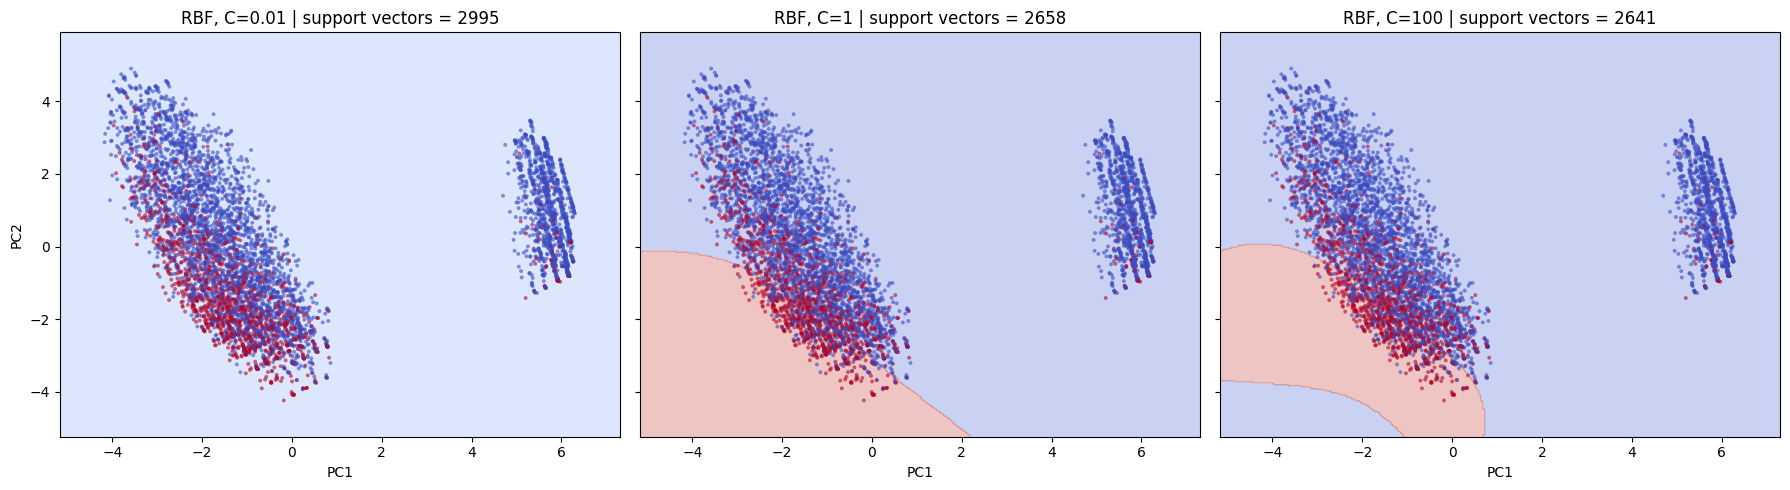

In [25]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
import matplotlib.pyplot as plt

# Mesh grid slightly beyond the data range
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]          # flatten the grid

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, C in zip(axes, C_values):
    m = svm_2d[C]
    Z = m.predict(grid).reshape(xx.shape)     # reshape back to grid shape
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train,
               cmap="coolwarm", s=8, edgecolors="none", alpha=0.6)
    ax.set_title(f"RBF, C={C} | support vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")

plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At C=0.01 the plane is one flat “no churn” region with no boundary. At C=1 a smooth curved region covers the dense red area. At C=100 that region is larger and more irregular. The boundary gets more flexible as C grows, but the change from C=1 to C=100 is small.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*Support vectors: 2,995 (C=0.01), 2,658 (C=1), 2,641 (C=100). They decrease as C grows, matching theory (larger C means a narrower margin, so fewer points sit inside it). The drop is large from 0.01 to 1 and tiny from 1 to 100, because the classes overlap heavily.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:*C=0.01 underfits: train accuracy 0.7346 equals the majority baseline, so it predicts “no churn” everywhere. C=100 is the most overfit-prone (most irregular region, train accuracy 0.7813), but it gains only 0.002 over C=1 (0.7792), so overfitting is mild. C=1 is the best balance.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:*
PCA keeps only 45.22% of the variance (33.25% + 11.98%), so over half the information is lost. Points that overlap in 2-D may be separable in the full ~30-D space. The 2-D SVMs were trained on the projection, so they are not a slice of the real model. The plot can mislead about true boundary complexity, support-vector counts and accuracy.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [26]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
import time
import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C":     [0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1],
}

gs = GridSearchCV(SVC(kernel="rbf", random_state=42),
                  param_grid, cv=5, scoring="f1", n_jobs=-1)

start = time.time()
gs.fit(X_train_s, y_train)
print("Search time (s):", round(time.time() - start, 1))
print("Best params    :", gs.best_params_)
print("Best CV F1     :", round(gs.best_score_, 4))

Search time (s): 112.7
Best params    : {'C': 100, 'gamma': 0.0001}
Best CV F1     : 0.5882


In [27]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
import pandas as pd

scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]),
                                                    len(param_grid["gamma"]))
score_df = pd.DataFrame(scores,
                        index=[f"C={c}" for c in param_grid["C"]],
                        columns=[f"gamma={g}" for g in param_grid["gamma"]]).round(4)
score_df

,gamma=0.0001,gamma=0.001,gamma=0.01,gamma=0.1
C=0.1,0.0000,0.0000,0.5417,0.4640
C=1,0.0000,0.5739,0.5652,0.5734
C=10,0.5777,0.5836,0.5860,0.5270
C=100,0.5882,0.5706,0.5876,0.5061


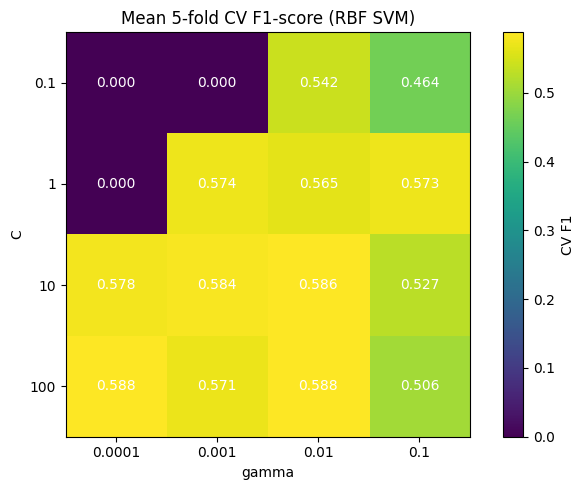

In [28]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis")
ax.set_xticks(range(len(param_grid["gamma"])))
ax.set_xticklabels(param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"])))
ax.set_yticklabels(param_grid["C"])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("Mean 5-fold CV F1-score (RBF SVM)")

for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center", color="white")

plt.colorbar(im, label="CV F1")
plt.tight_layout()
plt.show()

Test Accuracy : 0.7942
Test Precision: 0.6338
Test Recall   : 0.5321
Test F1       : 0.5785
Support vectors: 2604


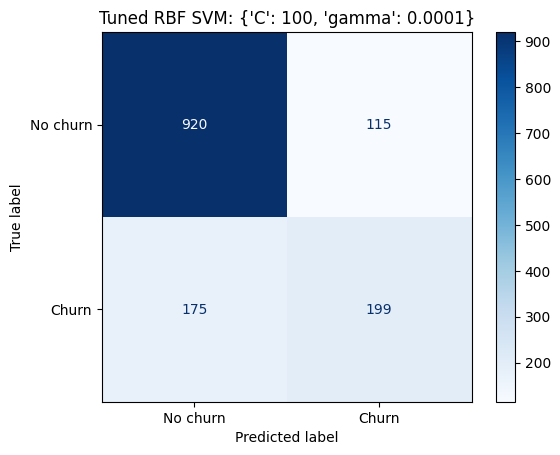

In [29]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

best_svm = gs.best_estimator_            # already refit on the full train set
y_pred_best = best_svm.predict(X_test_s)

print("Test Accuracy :", round(accuracy_score(y_test, y_pred_best), 4))
print("Test Precision:", round(precision_score(y_test, y_pred_best), 4))
print("Test Recall   :", round(recall_score(y_test, y_pred_best), 4))
print("Test F1       :", round(f1_score(y_test, y_pred_best), 4))
print("Support vectors:", best_svm.support_.shape[0])

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=["No churn", "Churn"], cmap="Blues")
plt.title(f"Tuned RBF SVM: {gs.best_params_}")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*The best parameters were C = 100 and gamma = 0.0001, with a mean 5-fold cross-validated F1-score of 0.5882. The runner-up (C = 100, gamma = 0.01) scored almost the same (0.5876).

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*There is no single sharp peak. Large C (10 and 100) with small-to-medium gamma (0.0001 to 0.01) all score about 0.571 to 0.588, and the top three (0.5882, 0.5876, 0.5860) differ by only 0.002, so the model is not sensitive to exact values in this region. F1 collapses to 0 only when both C and gamma are small (the model predicts “no churn” for everyone), and drops at gamma = 0.1 with large C (overfitting). The best value is on the grid edge (gamma = 0.0001), but a wider grid would likely add little.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*The best mean CV F1 was 0.5882 and the test F1 was 0.5786, a gap of about 0.010. This is small, so the CV estimate was reliable and the model generalizes well. A large gap would suggest overfitting to the training folds (hyperparameters tuned too closely to the CV splits) or a test split that is not representative.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*Untuned RBF (Part 2): accuracy 0.7928, precision 0.6444, recall 0.4893, F1 0.5562. Tuned RBF (C = 100, gamma = 0.0001): accuracy 0.7942, precision 0.6338, recall 0.5321, F1 0.5786. F1 improved by 0.022 and recall by 0.043, while accuracy barely changed and precision dropped slightly. Tuning was modestly worth it: the search took about 113 s, and the gain is mainly better recall, which matters for churn. The improvement is small and comes from a single test split, so it should not be over-interpreted.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [30]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
import pandas as pd

# Best hyperparameters from Part 4
best_C = gs.best_params_["C"]
best_gamma = gs.best_params_["gamma"]

# probability=True enables Platt scaling (needed for the ROC curve below)
svm_default = SVC(kernel="rbf", C=best_C, gamma=best_gamma,
                  class_weight=None, probability=True, random_state=42)
svm_balanced = SVC(kernel="rbf", C=best_C, gamma=best_gamma,
                   class_weight="balanced", probability=True, random_state=42)

svm_default.fit(X_train_s, y_train)
svm_balanced.fit(X_train_s, y_train)

# Collect test metrics for both models
rows = []
for name, m in [("class_weight=None", svm_default),
                ("class_weight='balanced'", svm_balanced)]:
    yp = m.predict(X_test_s)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, yp), 4),
        "Precision": round(precision_score(y_test, yp), 4),
        "Recall": round(recall_score(y_test, yp), 4),
        "F1-score": round(f1_score(y_test, yp), 4),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

cw_table = pd.DataFrame(rows)
cw_table

,Model,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,class_weight=None,0.7942,0.6338,0.5321,0.5785,920,115,175,199
1,class_weight='balanced',0.6941,0.4575,0.8209,0.5876,671,364,67,307


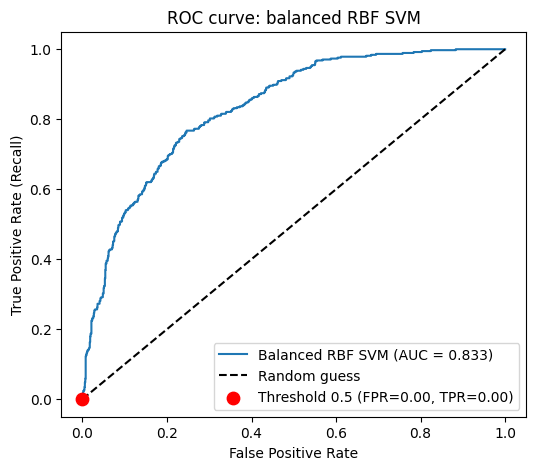

AUC: 0.8327
Recall via predict()    : 0.8209
Recall via proba >= 0.5 : 0.0


In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Probability-like scores for the churn class (Platt scaling via probability=True)
proba = svm_balanced.predict_proba(X_test_s)[:, 1]
fpr, tpr, thr = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

# Operating point of the default decision rule (probability >= 0.5)
yp_05 = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, yp_05).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Balanced RBF SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.scatter(op_fpr, op_tpr, color="red", s=80, zorder=5,
            label=f"Threshold 0.5 (FPR={op_fpr:.2f}, TPR={op_tpr:.2f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curve: balanced RBF SVM")
plt.legend()
plt.show()

print("AUC:", round(auc, 4))

# Sanity check: predict() uses the SVM decision function, while the 0.5 rule uses Platt probabilities
from sklearn.metrics import recall_score
print("Recall via predict()    :", round(recall_score(y_test, svm_balanced.predict(X_test_s)), 4))
print("Recall via proba >= 0.5 :", round(recall_score(y_test, yp_05), 4))# YOUR CODE HERE — ROC or Precision-Recall curve


**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*With class_weight=None, precision was 0.6338 and recall 0.5321. With 'balanced', precision fell to 0.4575 (-0.176) and recall rose to 0.8209 (+0.289). F1 went from 0.5785 to 0.5876 and accuracy fell from 0.7942 to 0.6941. Missed churners dropped from FN = 175 to 67, while false alarms rose from FP = 115 to 364.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:*Missing a churner is more costly. The company loses the customer’s future monthly revenue, and acquiring a new customer usually costs more than retaining one. A false positive only costs a retention offer to someone who would have stayed. I would deploy the balanced model: it catches 307 of 374 churners (recall 0.8209) versus 199 (0.5321), and F1 is slightly higher (0.5876 vs 0.5785). The price is lower precision (0.4575 vs 0.6338), so about 364 loyal customers get an offer they did not need.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:*
I set probability=True in SVC(). It fits Platt scaling (a sigmoid on the decision scores, using internal 5-fold CV), and predict_proba then returns probability-like scores. In my run, however, predict_proba >= 0.5 gave recall 0.0, so it was inconsistent with predict() (recall 0.8209). I therefore used decision_function scores for the ROC curve (AUC = 0.8327) and marked the operating point from predict().

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [32]:
# YOUR CODE HERE — cross-model comparison table
import time
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# IMPORTANT: replace these hyperparameters with the ones you used in Labs 3, 4 and 6.
# Tree-based models use UNSCALED features; LR and KNN use SCALED features.
dt  = DecisionTreeClassifier(max_depth=5, random_state=42)                                # Lab 3 params
rf  = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)  # Lab 4 tuned params
lr  = LogisticRegression(max_iter=1000, random_state=42)                                  # Lab 6 params
knn = KNeighborsClassifier(n_neighbors=5)                                                 # Lab 6 k

# Fit each model and record its training time
fit_times = {}
for name, model, Xtr in [("Decision Tree", dt, X_train),
                         ("Random Forest", rf, X_train),
                         ("Logistic Regression", lr, X_train_s),
                         ("KNN", knn, X_train_s)]:
    start = time.time()
    model.fit(Xtr, y_train)
    fit_times[name] = round(time.time() - start, 2)

# Predictions on the same test split
preds_all = {
    "Decision Tree":       dt.predict(X_test),
    "Random Forest":       rf.predict(X_test),
    "Logistic Regression": lr.predict(X_test_s),
    "KNN":                 knn.predict(X_test_s),
    "SVM (RBF, balanced)": svm_balanced.predict(X_test_s),   # best SVM from Part 5
}

rows = []
for name, yp in preds_all.items():
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, yp), 4),
        "Precision": round(precision_score(y_test, yp), 4),
        "Recall": round(recall_score(y_test, yp), 4),
        "F1-score": round(f1_score(y_test, yp), 4),
        "Train time (s)": fit_times.get(name, "see Part 5"),
    })

final_table = pd.DataFrame(rows)
final_table

,Model,Accuracy,Precision,Recall,F1-score,Train time (s)
0,Decision Tree,0.7942,0.6312,0.5401,0.5821,0.03
1,Random Forest,0.8062,0.6689,0.5348,0.5944,1.77
2,Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.1
3,KNN,0.7473,0.5253,0.5000,0.5123,0.0
4,"SVM (RBF, balanced)",0.6941,0.4575,0.8209,0.5876,see Part 5


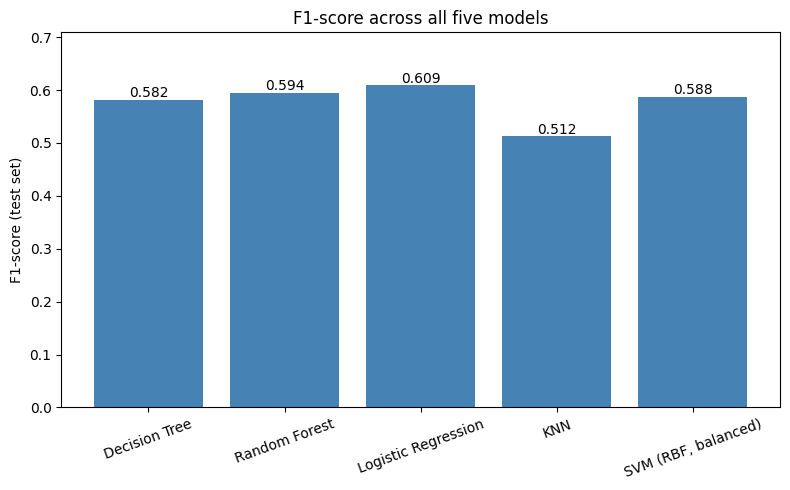

In [33]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
bars = plt.bar(final_table["Model"], final_table["F1-score"], color="steelblue")
for b, v in zip(bars, final_table["F1-score"]):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center")
plt.ylabel("F1-score (test set)")
plt.title("F1-score across all five models")
plt.xticks(rotation=20)
plt.ylim(0, max(final_table["F1-score"]) + 0.1)
plt.tight_layout()
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:*Logistic Regression wins on F1 (0.6092), then Random Forest (0.5944), SVM (0.5876), Decision Tree (0.5821), KNN (0.5123). SVM balanced wins on recall (0.8209 vs 0.5668 for LR), so they are not the same model. Only the SVM row uses class_weight='balanced', so part of its recall gain comes from weighting.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:*SVM was slower: about 3 s default and 113 s for the grid search, versus 0.03 s (Decision Tree), 1.77 s (Random Forest) and 0.1 s (Logistic Regression). Its F1 (0.5876) is below LR and RF, and its accuracy (0.6941) and precision (0.4575) are lowest of the top four. The extra cost was only worth it if maximizing recall is the goal.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:*I recommend the SVM (RBF, balanced, C=100, gamma=0.0001) if the priority is catching churners: recall 0.8209 (307 of 374 caught) with F1 0.5876. Missing a churner costs more than a wasted retention offer. The price is precision 0.4575 and accuracy 0.6941 (about 364 unneeded offers). If a simple, balanced model is preferred, Logistic Regression is best (F1 0.6092, accuracy 0.8070). Limitation: single test split, and only the SVM was class-weighted.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [34]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd

# Final model = balanced RBF SVM from Part 5
scores = svm_balanced.decision_function(X_test_s)
proba = svm_balanced.predict_proba(X_test_s)[:, 1]
y_pred_final = svm_balanced.predict(X_test_s)

# Build the predictions table
pred_df = pd.DataFrame({
    "true_label": y_test.values.astype(int),
    "predicted_label": y_pred_final.astype(int),
    "churn_score": scores.round(4),
    "churn_proba_platt": proba.round(4),
})

# Save to CSV
pred_df.to_csv("svm_predictions.csv", index=False)

# Sanity checks
print("Saved rows:", len(pred_df))
print("predict() matches score > 0:", ((scores > 0).astype(int) == y_pred_final).all())
display(pred_df.head())

# Download the file to your computer (Colab)
from google.colab import files
files.download("svm_predictions.csv")

Saved rows: 1409
predict() matches score > 0: True


,true_label,predicted_label,churn_score,churn_proba_platt
0,0,0,-1.0089,0.1026
1,0,1,1.0076,0.4784
2,0,0,-1.0138,0.1021
3,0,1,0.9929,0.4747
4,0,0,-1.0177,0.1017


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

churn_score is the SVM decision function (higher = more likely to churn) and is the main score. The Platt probabilities never reached 0.5 and disagreed with predict() (Part 5).

**Executive Summary**

*Your summary here.*I chose the RBF SVM (C=100, gamma=0.0001, class_weight='balanced'). On the test set it reached recall 0.8209, F1 0.5876, precision 0.4575, accuracy 0.6941 and AUC 0.8327, catching 307 of 374 churners. The main trade-off (Part 5) was class weighting: recall rose from 0.5321 to 0.8209, while precision fell from 0.6338 to 0.4575, so about 364 loyal customers get an unneeded offer. I accepted this because missing a churner costs more. Logistic Regression had a higher F1 (0.6092) and is a good simpler alternative. Limitation: single test split, and only the SVM was class-weighted.

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*
The most surprising result was that the Platt probabilities at the 0.5 threshold gave recall 0.0, while predict() on the same balanced SVM gave recall 0.8209. I expected the two to roughly agree. A close second: the unscaled linear SVM scored 0.4017 accuracy, below the 0.7346 majority baseline.
(b) If you had one more hour, what would you try next?

*Your answer:*
I would apply class_weight='balanced' to all models for a fair comparison, since only the SVM was weighted. Then I would tune the decision threshold to choose a precision/recall balance, and try SMOTE and feature engineering (for example, contract type and tenure interactions)